# # 08 · Recurrent language models: RNN, LSTM, GRU
#
# Before Transformers: read one token at a time and carry a fixed-size **hidden state** `h_t = f(h_{t-1}, x_t)`.
# Cost is O(T) and inference memory is constant — but training is sequential and long-range gradients vanish.
# LSTM/GRU add **gates** that let the state be preserved or overwritten selectively.

---

### At a glance

| | |
|---|---|
| **Family** | Recurrent networks |
| **Representative models** | RNN, LSTM, GRU, ELMo, early seq2seq |
| **Core idea** | Process tokens one by one and compress history into a fixed-size hidden state. |
| **Compute / memory** | O(T) time, O(1) inference state; sequential training |
| **Dataset** | tiny-Shakespeare (char level) – see notebook 00 |
| **Runtime** | ≈ 93 s on a laptop CPU |

### What you will learn

- Train RNN, LSTM and GRU language models
- Measure how far back gradients reach
- Open up the LSTM gates

> Environment: `uv sync` then `uv run jupyter lab` (kernel **LLM Architecture (uv)**). Data: `uv run python scripts/prepare_data.py`.

---

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np, seaborn as sns
from llmarch import *
setup_style()
set_seed(0); device = get_device(); STEPS = 1200
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

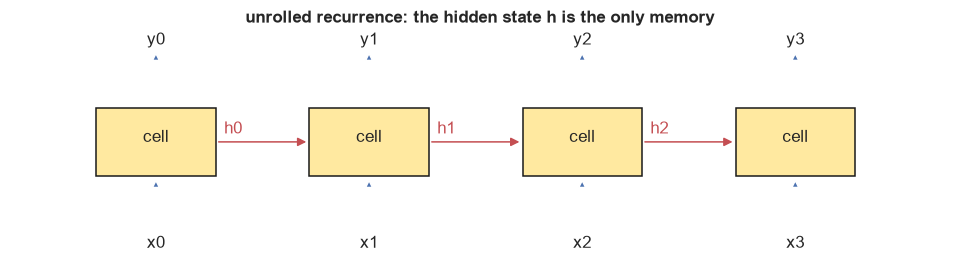

In [2]:
fig, ax = plt.subplots(figsize=(11, 2.6)); ax.axis("off"); ax.set_xlim(0, 11); ax.set_ylim(0, 2.6)
for t in range(4):
    x = 1 + 2.5 * t
    ax.add_patch(plt.Rectangle((x, .9), 1.4, .8, fc="#ffe9a0", ec="k")); ax.text(x + .7, 1.3, "cell", ha="center")
    ax.annotate("", (x + .7, .9), (x + .7, .2), arrowprops=dict(arrowstyle="-|>")); ax.text(x + .7, .05, f"x{t}", ha="center")
    ax.annotate("", (x + .7, 2.4), (x + .7, 1.7), arrowprops=dict(arrowstyle="-|>")); ax.text(x + .7, 2.45, f"y{t}", ha="center")
    if t < 3: ax.annotate("", (x + 2.5, 1.3), (x + 1.4, 1.3), arrowprops=dict(arrowstyle="-|>", color="C3")); ax.text(x + 1.5, 1.4, f"h{t}", color="C3")
ax.set_title("unrolled recurrence: the hidden state h is the only memory"); plt.show()

# ## Models (PyTorch's cuDNN-style kernels)

== RNN 82,753 params


== LSTM 280,897 params


== GRU 214,849 params


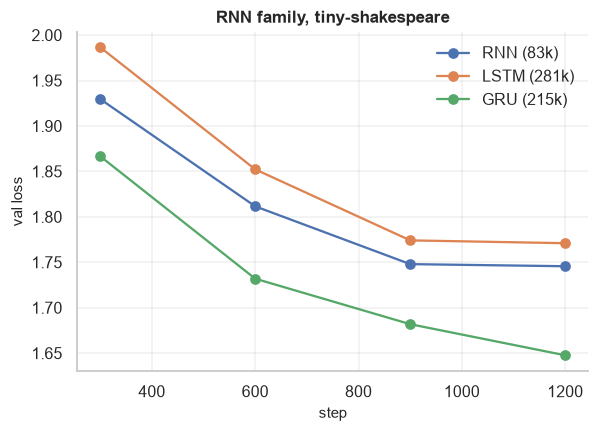

In [3]:
class RNNLM(nn.Module):
    def __init__(s, V, kind, d=128, n=2):
        super().__init__(); s.emb = nn.Embedding(V, d); s.rnn = {"RNN": nn.RNN, "LSTM": nn.LSTM, "GRU": nn.GRU}[kind](d, d, n, batch_first=True)
        s.head = nn.Linear(d, V)
    def forward(s, x): return s.head(s.rnn(s.emb(x))[0])
models, hists = {}, {}
for kind in ["RNN", "LSTM", "GRU"]:
    set_seed(0); models[kind] = RNNLM(V, kind); print("==", kind, f"{count_params(models[kind]):,} params")
    hists[kind] = train_lm(models[kind], train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=300, verbose=False)
save_result("08 LSTM", models["LSTM"], hists["LSTM"]); save_result("08 GRU", models["GRU"], hists["GRU"])
plt.figure(figsize=(6, 4))
for k, h in hists.items(): plt.plot(h["val_step"], h["val"], "o-", label=f"{k} ({count_params(models[k])/1e3:.0f}k)")
plt.xlabel("step"); plt.ylabel("val loss"); plt.legend(); plt.grid(alpha=.3); plt.title("RNN family, tiny-shakespeare"); plt.show()

# ## Sample

In [4]:
start = torch.zeros((1, 1), dtype=torch.long, device=device)
print(data["decode"](generate(models["LSTM"], start, 300, temperature=0.8, top_k=10)[0].tolist()))


But stirs
The will daught op to near:
That hand to thuser, I have this for when as my to but never some thou mother me;
And sear'dst mine to she secold of the causing to here whither frose of that worns shall and mest for the many that maily fellace
The shall and the words.

MARTICUS:
And my find a 


# ## Why gates? Gradient flow back in time
# We take the loss at the **last** position and measure how strongly each earlier input embedding influences it.
# The plain RNN's influence collapses exponentially (vanishing gradient); LSTM/GRU keep a much longer memory.

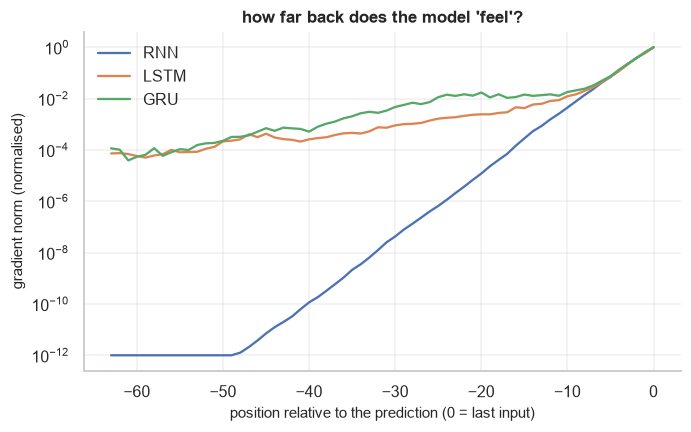

In [5]:
x, _ = get_batch(val, 64, 64, device)
plt.figure(figsize=(7, 4))
for kind, m in models.items():
    m.eval(); m.zero_grad(); e = m.emb(x).detach().requires_grad_(True); out = m.head(m.rnn(e)[0][:, -1])
    out.logsumexp(-1).sum().backward(); g = e.grad.norm(dim=-1).mean(0).cpu()
    plt.semilogy(range(-63, 1), (g / g.max()).clamp(min=1e-12), label=kind)
plt.xlabel("position relative to the prediction (0 = last input)"); plt.ylabel("gradient norm (normalised)"); plt.legend(); plt.grid(alpha=.3, which="both"); plt.title("how far back does the model 'feel'?"); plt.show()

# ## Inside an LSTM: the gates
# We recompute the first-layer LSTM by hand from the trained weights to expose `i, f, g, o` and the cell state.
# * **forget gate f** — how much of the old cell state to keep
# * **input gate i** — how much new information to write
# * **output gate o** — how much of the cell to reveal

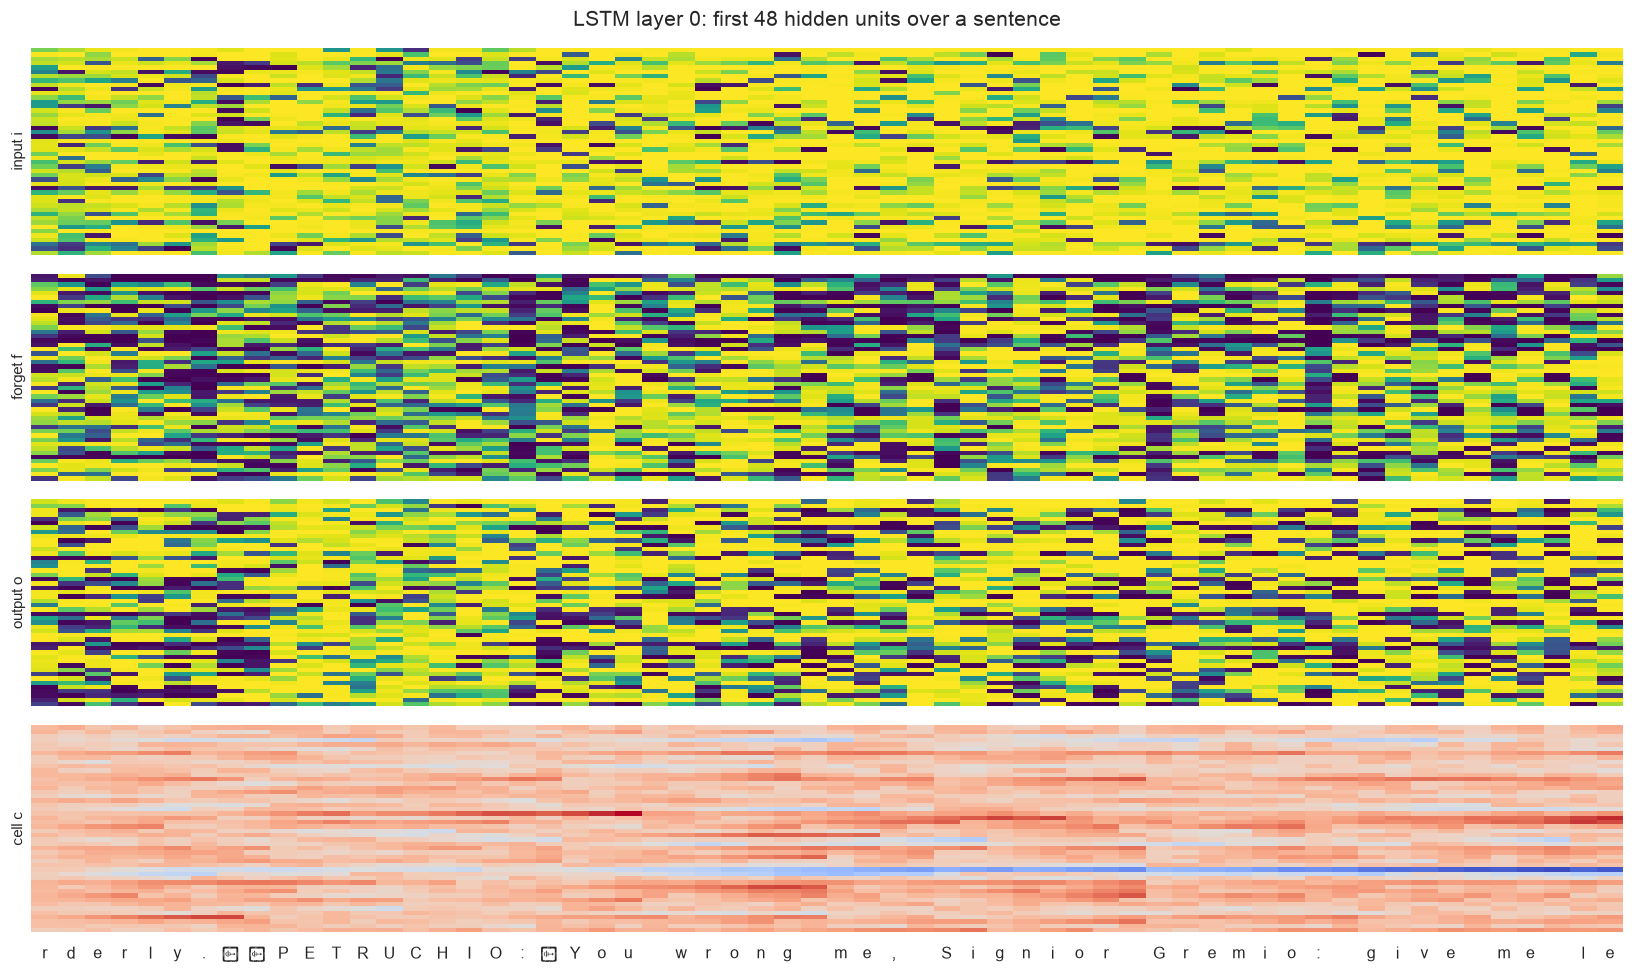

In [6]:
lstm = models["LSTM"].rnn; W_ih, W_hh, b = lstm.weight_ih_l0, lstm.weight_hh_l0, lstm.bias_ih_l0 + lstm.bias_hh_l0
sent = val[300:360]; emb = models["LSTM"].emb(sent.to(device)).detach(); H = lstm.hidden_size
h = torch.zeros(H, device=device); c = torch.zeros(H, device=device); G = {"input i": [], "forget f": [], "output o": [], "cell c": []}
with torch.no_grad():
    for t in range(len(sent)):
        i, f, g, o = (W_ih @ emb[t] + W_hh @ h + b).chunk(4); i, f, g, o = i.sigmoid(), f.sigmoid(), g.tanh(), o.sigmoid()
        c = f * c + i * g; h = o * c.tanh()
        for k, v in zip(G, [i, f, o, c]): G[k].append(v.cpu())
labels = [("⏎" if ch == "\n" else ch) for ch in data["decode"](sent.tolist())]
fig, axs = plt.subplots(4, 1, figsize=(15, 9))
for ax, (k, v) in zip(axs, G.items()):
    sns.heatmap(torch.stack(v).T[:48].numpy(), ax=ax, cmap="coolwarm" if "cell" in k else "viridis", cbar=False, xticklabels=labels if k == "cell c" else False, yticklabels=False); ax.set_ylabel(k)
plt.suptitle("LSTM layer 0: first 48 hidden units over a sentence"); plt.tight_layout(); plt.show()

# ## Constant-size state vs growing KV cache

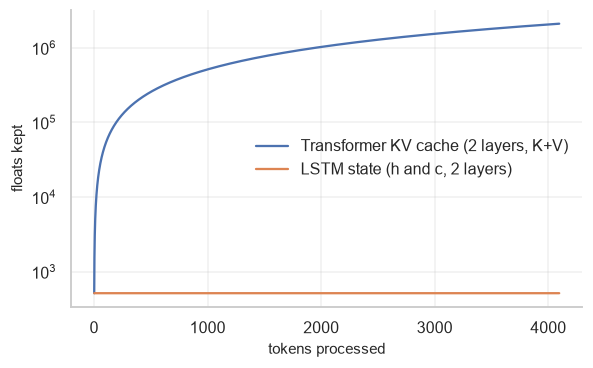

In [7]:
T = np.arange(1, 4097); d = 128
plt.figure(figsize=(6, 3.5)); plt.plot(T, T * 2 * d * 2, label="Transformer KV cache (2 layers, K+V)"); plt.plot(T, np.full_like(T, 2 * 2 * d), label="LSTM state (h and c, 2 layers)")
plt.xlabel("tokens processed"); plt.ylabel("floats kept"); plt.yscale("log"); plt.legend(); plt.grid(alpha=.3); plt.show()

---

## Key takeaways

- A plain RNN's gradient vanishes exponentially with distance; gates give LSTM/GRU a protected memory path.
- Constant-size state makes inference cheap, but everything must be compressed into it.
- Training cannot be parallelised over time, which is why Transformers took over.

## References

- Hochreiter & Schmidhuber, *Long Short-Term Memory*, Neural Computation (1997)
- [Cho et al., *GRU* (2014)](https://arxiv.org/abs/1406.1078)
- [Karpathy, *The Unreasonable Effectiveness of RNNs* (blog, 2015)](https://karpathy.github.io/2015/05/21/rnn-effectiveness/)

---
*← previous: `07_mixture_of_experts`  ·  next: `09_state_space_mamba` →*